# Phase 5 · Rehearsal on synthetic data

Before fitting the discrete-time hazard model to the real ICU data, we fit it to data where the
answer is known (brief, Tutorial 11). We simulate patients from a hazard model with chosen
coefficients and run them through **the same code** used on the real export:
`add_targets` (T_i and the hazard risk set) → `fit_hazard` (binomial GLM with one baseline α per
ICU-time group). If the pipeline is right, the estimates come back close to the truth.

**True model** (the brief's example), per patient *i* and ICU hour *t*, while still at risk:

$$\operatorname{logit} h_{it} = \alpha + 0.8\,x_{1,it} + 0.5\,x_{2,it} + 0.03\,\text{age}_i,\qquad \alpha = -5 \text{ in every ICU-time group}$$

- `x1`, `x2`: per-patient AR(1) processes (φ = 0.8, unit variance), so covariates change hour by hour.
- `age` ~ N(60, 15), fixed per patient.
- A non-septic stay is censored at a random length of 8–72 h. Once the event fires at T_i,
  `label_sepsis = 1` from T_i to the end of the stay, which runs 0–10 more hours (like the
  challenge label).

The code lives in `src/sepsis_mining/simulate.py`; this notebook only runs and explains it.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from sepsis_mining.hazard import fit_hazard
from sepsis_mining.simulate import BETA, recovery_table, simulate_cohort
from sepsis_mining.targets import add_targets

pl.Config.set_tbl_rows(20)
ALPHA, SEED, N = -5.0, 0, 5000

## 1. Simulate a cohort and build the targets

In [2]:
frame = add_targets(simulate_cohort(N, SEED, BETA, alpha=ALPHA))
patients = frame.group_by("patient_id").agg(
    pl.col("label_onset_row_idx").first().is_not_null().alias("septic"), pl.len().alias("hours")
)
risk_set = frame.filter("label_hazard_at_risk")
print(
    f"patients {patients.height:,}  ·  septic {patients['septic'].mean():.1%}  ·  "
    f"patient-hours {frame.height:,}  ·  median stay {patients['hours'].median():.0f} h"
)
print(
    f"risk-set rows {risk_set.height:,}  ·  events {risk_set['label_hazard_event'].sum():,}  ·  "
    f"event rate {risk_set['label_hazard_event'].mean():.3%}"
)

# One event per septic patient, and none after it: the risk set is built correctly.
assert risk_set["label_hazard_event"].sum() == patients["septic"].sum()
risk_set.group_by("feat_icu_time_group").agg(
    pl.len().alias("rows"), pl.col("label_hazard_event").sum().alias("events")
).sort("rows", descending=True)

patients 5,000  ·  septic 77.9%  ·  patient-hours 101,465  ·  median stay 16 h
risk-set rows 81,951  ·  events 3,893  ·  event rate 4.750%


feat_icu_time_group,rows,events
str,u32,u32
"""0-6""",26000,1422
"""13-24""",21394,938
"""7-12""",18601,894
"""25-48""",13983,558
""">48""",1973,81


Most simulated patients become septic: the brief's example coefficients give a hazard of about
4% per hour at age 60. The real data's hazard event rate is about 0.19% per hour (brief §6). The
high rate is fine for a code rehearsal: more events mean tighter intervals. The point is
recovering known numbers, not realism.

## 2. Fit the hazard model and compare with the truth

The fit uses only the risk set: every hour of non-septic patients, and the hours of septic
patients up to and including T_i.

In [3]:
coefs = fit_hazard(frame, list(BETA))
recovery = recovery_table(coefs, ALPHA, BETA)
recovery

term,true,estimate,ci_low,ci_high,covered
str,f64,f64,f64,f64,bool
"""alpha[0-6]""",-5.0,-4.936183,-5.09924,-4.773126,true
"""alpha[7-12]""",-5.0,-4.950036,-5.112951,-4.787122,true
"""alpha[13-24]""",-5.0,-4.952905,-5.110909,-4.794901,true
"""alpha[25-48]""",-5.0,-4.959337,-5.119703,-4.79897,true
"""alpha[>48]""",-5.0,-4.89737,-5.159851,-4.634889,true
"""feat_x1""",0.8,0.79941,0.764033,0.834788,true
"""feat_x2""",0.5,0.476015,0.442108,0.509923,true
"""feat_age""",0.03,0.02887,0.026537,0.031203,true


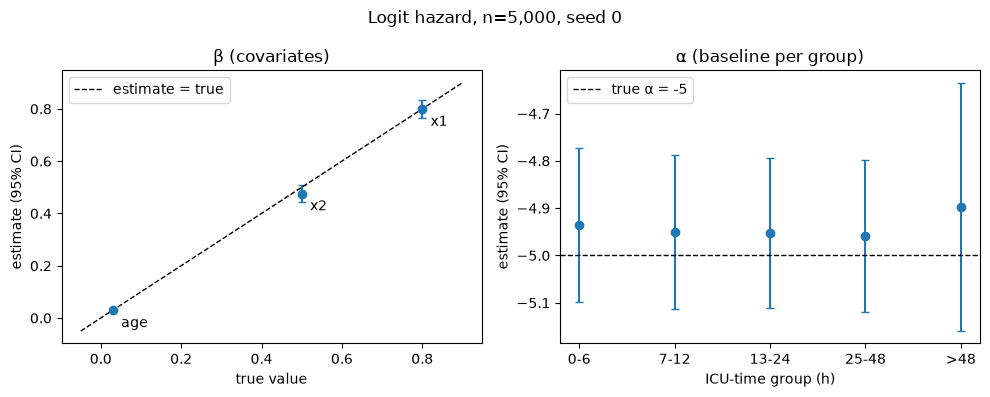

In [4]:
def plot_recovery(table, title):
    beta = table.filter(~pl.col("term").str.starts_with("alpha["))
    alpha = table.filter(pl.col("term").str.starts_with("alpha["))
    fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4))

    t, e = beta["true"].to_numpy(), beta["estimate"].to_numpy()
    err = np.vstack([e - beta["ci_low"].to_numpy(), beta["ci_high"].to_numpy() - e])
    left.errorbar(t, e, yerr=err, fmt="o", capsize=3)
    for x, y, name in zip(t, e, beta["term"], strict=True):
        left.annotate(
            name.removeprefix("feat_"), (x, y), textcoords="offset points", xytext=(6, -12)
        )
    left.plot([-0.05, 0.9], [-0.05, 0.9], "k--", lw=1, label="estimate = true")
    left.set(xlabel="true value", ylabel="estimate (95% CI)", title="β (covariates)")
    left.legend(loc="upper left")

    e = alpha["estimate"].to_numpy()
    err = np.vstack([e - alpha["ci_low"].to_numpy(), alpha["ci_high"].to_numpy() - e])
    groups = [g.removeprefix("alpha[").removesuffix("]") for g in alpha["term"]]
    right.errorbar(groups, e, yerr=err, fmt="o", capsize=3)
    right.axhline(
        alpha["true"][0], color="k", ls="--", lw=1, label=f"true α = {alpha['true'][0]:g}"
    )
    right.set(
        xlabel="ICU-time group (h)", ylabel="estimate (95% CI)", title="α (baseline per group)"
    )
    right.legend(loc="upper left")

    fig.suptitle(title)
    fig.tight_layout()


plot_recovery(recovery, f"Logit hazard, n={N:,}, seed {SEED}")

Every 95% interval covers its true value. The α panel shows the five ICU-time-group baselines
all near −5. The >48 h interval is the widest because only about 2,000 risk-set rows reach that group (the table in section 1); real stays that long are rare as well. In this seed they sit slightly above −5 together. That is chance, not bias: age is
not centred, so a small error in β_age (0.029 vs 0.03) times a mean age of 60 shifts every α by
about +0.06. Section 4 checks this over many seeds.

## 3. Does the rehearsal catch a wrong risk set?

A recovery check only means something if a broken pipeline **fails** it. A realistic mistake is
to use the challenge label directly as the hazard outcome on every row. That counts each
post-onset hour as another event and keeps patients "at risk" after they have already become
septic.

In [5]:
broken = frame.with_columns(
    label_hazard_at_risk=pl.lit(True), label_hazard_event=pl.col("label_sepsis") == 1
)
broken_recovery = recovery_table(fit_hazard(broken, list(BETA)), ALPHA, BETA)
pl.DataFrame(
    {
        "term": recovery["term"],
        "true": recovery["true"],
        "correct risk set": recovery["estimate"],
        "label_sepsis on all rows": broken_recovery["estimate"],
        "broken covered": broken_recovery["covered"],
    }
)

term,true,correct risk set,label_sepsis on all rows,broken covered
str,f64,f64,f64,bool
"""alpha[0-6]""",-5.0,-4.936183,-3.755812,false
"""alpha[7-12]""",-5.0,-4.950036,-2.976453,false
"""alpha[13-24]""",-5.0,-4.952905,-2.930126,false
"""alpha[25-48]""",-5.0,-4.959337,-2.841413,false
"""alpha[>48]""",-5.0,-4.89737,-2.61696,false
"""feat_x1""",0.8,0.79941,0.539958,false
"""feat_x2""",0.5,0.476015,0.307034,false
"""feat_age""",0.03,0.02887,0.031328,false


With the broken risk set, no interval covers the truth. The baselines rise because post-onset
hours inflate the event rate, and the effects of x1 and x2 shrink toward zero. So the rehearsal does detect
this mistake.

## 4. Are the 95% intervals honest? Coverage over many seeds

One seed is one draw. If the pipeline is unbiased and the standard errors are right, each 95%
interval should cover its true value in about 95% of independent simulations.

In [6]:
seeds = range(1, 41)
rows = []
for s in seeds:
    t = recovery_table(
        fit_hazard(add_targets(simulate_cohort(2000, s, BETA)), list(BETA)), ALPHA, BETA
    )
    rows.append(t.with_columns(seed=pl.lit(s)))
runs = pl.concat(rows)
runs.group_by("term", maintain_order=True).agg(
    pl.col("true").first(),
    pl.col("estimate").mean().alias("mean estimate"),
    (pl.col("estimate") - pl.col("true")).mean().alias("bias"),
    pl.col("covered").mean().alias("coverage"),
)

term,true,mean estimate,bias,coverage
str,f64,f64,f64,f64
"""alpha[0-6]""",-5.0,-4.993851,0.006149,0.975
"""alpha[7-12]""",-5.0,-4.999626,0.000374,0.975
"""alpha[13-24]""",-5.0,-5.008015,-0.008015,0.925
"""alpha[25-48]""",-5.0,-4.996208,0.003792,0.975
"""alpha[>48]""",-5.0,-5.020104,-0.020104,0.925
"""feat_x1""",0.8,0.801745,0.001745,0.975
"""feat_x2""",0.5,0.501322,0.001322,0.925
"""feat_age""",0.03,0.029945,-0.000055,0.975


Mean estimates sit on the truth and coverage is near 95% for every term (with 40 seeds, anything
from roughly 85% to 100% is consistent with 95%). The seed-0 shift in α from section 2 averages
out.

## 5. Complementary log-log link

Swapping the logit link for cloglog makes the model a discrete proportional-hazards ("grouped
Cox") model (Tutorial 7). Simulating and fitting under cloglog should recover the truth just as
well.

In [7]:
cloglog = recovery_table(
    fit_hazard(
        add_targets(simulate_cohort(N, SEED, BETA, link="cloglog")), list(BETA), link="cloglog"
    ),
    ALPHA,
    BETA,
)
cloglog

term,true,estimate,ci_low,ci_high,covered
str,f64,f64,f64,f64,bool
"""alpha[0-6]""",-5.0,-4.932697,-5.087464,-4.77793,true
"""alpha[7-12]""",-5.0,-4.944229,-5.09843,-4.790029,true
"""alpha[13-24]""",-5.0,-4.940957,-5.090674,-4.79124,true
"""alpha[25-48]""",-5.0,-4.973219,-5.125847,-4.820591,true
"""alpha[>48]""",-5.0,-4.870241,-5.124834,-4.615648,true
"""feat_x1""",0.8,0.801911,0.768982,0.83484,true
"""feat_x2""",0.5,0.475208,0.443368,0.507048,true
"""feat_age""",0.03,0.028813,0.026618,0.031009,true


## 6. What this does and doesn't validate

**It validates the code and the logic** (methodological, not medical):

- **Target construction:** T_i is taken from the first positive label, there is exactly one event per
  septic patient, and the hours after the event are dropped from the risk set.
- **The likelihood:** it is fitted as a binomial GLM on the person-period table, with ICU-time
  groups coded as one α each and no global intercept.
- **Both link functions** (logit, cloglog), and **honest 95% intervals**: coverage is near
  nominal over repeated simulations.
- **The rehearsal can detect a wrong risk set** (section 3), so a pass is informative.

**It does not validate:**

- **Anything clinical.** The coefficients are invented, and recovering them says nothing about
  sepsis.
- **The real data's complications.** The simulated covariates are fully observed and regularly
  sampled. Real data has informative missingness (the source of the hospital shortcut),
  irregular lab draws, LOCF, and a shift between hospitals A and B. `preprocess` and the S1/S2
  feature sets are not exercised here.
- **Misspecification.** The true model is inside the fitted model class. On real data, the true
  hazard need not be logit-linear in the features, and α need not be a step function of ICU
  time.
- **Competing risks and informative censoring.** The simulated censoring is independent of risk.
  In real data, discharge and death are not.
- **The prospective target.** This exercises the hazard model only. The honest future-window
  target Y_6 and the cumulative-hazard leakage demo are separate (Phase 7).